# Machine Learning

In [1]:
import pandas as pd

df_demand = pd.read_csv('demand.csv')

df_demand

,order_id,order_date,required_date,shipped_date,store_id,store_name,product_id,product_name,brand_id,brand_name,category_id,category_name,model_year,quantity,price
0,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,20,Electra Townie Original 7D EQ - Women's - 2016,1,Electra,3,Cruisers Bicycles,2016,1,599.99
1,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,8,Trek Remedy 29 Carbon Frameset - 2016,9,Trek,6,Mountain Bikes,2016,2,1799.99
2,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,10,Surly Straggler - 2016,8,Surly,4,Cyclocross Bicycles,2016,2,1549.00
3,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,16,Electra Townie Original 7D EQ - 2016,1,Electra,3,Cruisers Bicycles,2016,2,599.99
4,1,2016-01-01,2016-01-03,2016-01-03,1,Santa Cruz Bikes,4,Trek Fuel EX 8 29 - 2016,9,Trek,6,Mountain Bikes,2016,1,2899.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4717,1614,2018-11-28,2018-11-28,NaN,3,Rowlett Bikes,159,Trek Emonda ALR 6 - 2018,9,Trek,7,Road Bikes,2018,2,2299.99
4718,1614,2018-11-28,2018-11-28,NaN,3,Rowlett Bikes,213,Electra Cruiser 1 - 2016/2017/2018,1,Electra,3,Cruisers Bicycles,2018,2,269.99
4719,1615,2018-12-28,2018-12-28,NaN,3,Rowlett Bikes,197,Trek Verve+ Lowstep - 2018,9,Trek,5,Electric Bikes,2018,2,2299.99
4720,1615,2018-12-28,2018-12-28,NaN,3,Rowlett Bikes,214,Electra Tiger Shark 3i - 2018,1,Electra,3,Cruisers Bicycles,2018,1,899.99


Deleting not useful columns for ML

In [2]:
columns_delete = ['order_id', 'required_date', 'shipped_date', 'store_name', 'product_id', 'product_name', 'brand_name', 'category_name', 'price', 'model_year']

df = df_demand.drop(columns=[col for col in columns_delete if col in df_demand.columns])

df

,order_date,store_id,brand_id,category_id,quantity
0,2016-01-01,1,1,3,1
1,2016-01-01,1,9,6,2
2,2016-01-01,1,8,4,2
3,2016-01-01,1,1,3,2
4,2016-01-01,1,9,6,1
...,...,...,...,...,...
4717,2018-11-28,3,9,7,2
4718,2018-11-28,3,1,3,2
4719,2018-12-28,3,9,5,2
4720,2018-12-28,3,1,3,1


Creating month column

In [3]:
df['order_date'] = pd.to_datetime(df['order_date'])

df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month

df = df.drop(columns=['order_date'])

df

,store_id,brand_id,category_id,quantity,order_year,order_month
0,1,1,3,1,2016,1
1,1,9,6,2,2016,1
2,1,8,4,2,2016,1
3,1,1,3,2,2016,1
4,1,9,6,1,2016,1
...,...,...,...,...,...,...
4717,3,9,7,2,2018,11
4718,3,1,3,2,2018,11
4719,3,9,5,2,2018,12
4720,3,1,3,1,2018,12


Taking out 2018 empty values from may in advance

In [4]:
df = df[~((df['order_year'] == 2018) & (df['order_month'] >= 5))]
df

,store_id,brand_id,category_id,quantity,order_year,order_month
0,1,1,3,1,2016,1
1,1,9,6,2,2016,1
2,1,8,4,2,2016,1
3,1,1,3,2,2016,1
4,1,9,6,1,2016,1
...,...,...,...,...,...,...
4685,2,7,3,2,2018,4
4686,2,2,6,1,2018,4
4687,2,9,1,2,2018,4
4688,2,1,3,2,2018,4


Grouping rows

In [5]:
df= df.groupby(['store_id', 'brand_id', 'category_id', 'order_year', 'order_month'])['quantity'].sum().reset_index()
df

,store_id,brand_id,category_id,order_year,order_month,quantity
0,1,1,1,2016,1,6
1,1,1,1,2016,2,8
2,1,1,1,2016,3,2
3,1,1,1,2016,4,6
4,1,1,1,2016,5,3
...,...,...,...,...,...,...
970,3,9,7,2017,12,1
971,3,9,7,2018,1,4
972,3,9,7,2018,2,6
973,3,9,7,2018,3,5


Accumulative months

In [6]:
df['order_month'] = (df['order_year'] - 2016) * 12 + df['order_month']
df

,store_id,brand_id,category_id,order_year,order_month,quantity
0,1,1,1,2016,1,6
1,1,1,1,2016,2,8
2,1,1,1,2016,3,2
3,1,1,1,2016,4,6
4,1,1,1,2016,5,3
...,...,...,...,...,...,...
970,3,9,7,2017,24,1
971,3,9,7,2018,25,4
972,3,9,7,2018,26,6
973,3,9,7,2018,27,5


Train Test Split

In [7]:
train = df[df['order_year'].isin([2016, 2017])]
test = df[df['order_year'] == 2018]

In [8]:
train

,store_id,brand_id,category_id,order_year,order_month,quantity
0,1,1,1,2016,1,6
1,1,1,1,2016,2,8
2,1,1,1,2016,3,2
3,1,1,1,2016,4,6
4,1,1,1,2016,5,3
...,...,...,...,...,...,...
966,3,9,7,2017,20,6
967,3,9,7,2017,21,5
968,3,9,7,2017,22,1
969,3,9,7,2017,23,1


One Hot Encoding

In [9]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ['store_id', 'brand_id', 'category_id']

known_categories = [
    sorted(df['store_id'].unique()),
    sorted(df['brand_id'].unique()),
    sorted(df['category_id'].unique())
]

encoder = OneHotEncoder(sparse_output=False, drop=None, handle_unknown='ignore', categories=known_categories)

encoded_train = encoder.fit_transform(train[categorical_cols])
encoded_test = encoder.transform(test[categorical_cols])

encoded_col_names = encoder.get_feature_names_out(categorical_cols)

train_encoded_df = pd.DataFrame(encoded_train, columns=encoded_col_names, index=train.index)
test_encoded_df = pd.DataFrame(encoded_test, columns=encoded_col_names, index=test.index)

other_cols = [col for col in train.columns if col not in categorical_cols]

train_final = pd.concat([train[other_cols], train_encoded_df], axis=1)
test_final = pd.concat([test[other_cols], test_encoded_df], axis=1)

X_train = train_final.drop(columns=['quantity', 'order_year'])
y_train = train_final['quantity']

X_test = test_final.drop(columns=['quantity', 'order_year'])
y_test = test_final['quantity']

In [10]:
X_train

,order_month,store_id_1,store_id_2,store_id_3,brand_id_1,brand_id_2,brand_id_3,brand_id_4,brand_id_5,brand_id_6,brand_id_7,brand_id_8,brand_id_9,category_id_1,category_id_2,category_id_3,category_id_4,category_id_5,category_id_6,category_id_7
0,1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
966,20,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
967,21,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
968,22,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
969,23,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Features correlation check

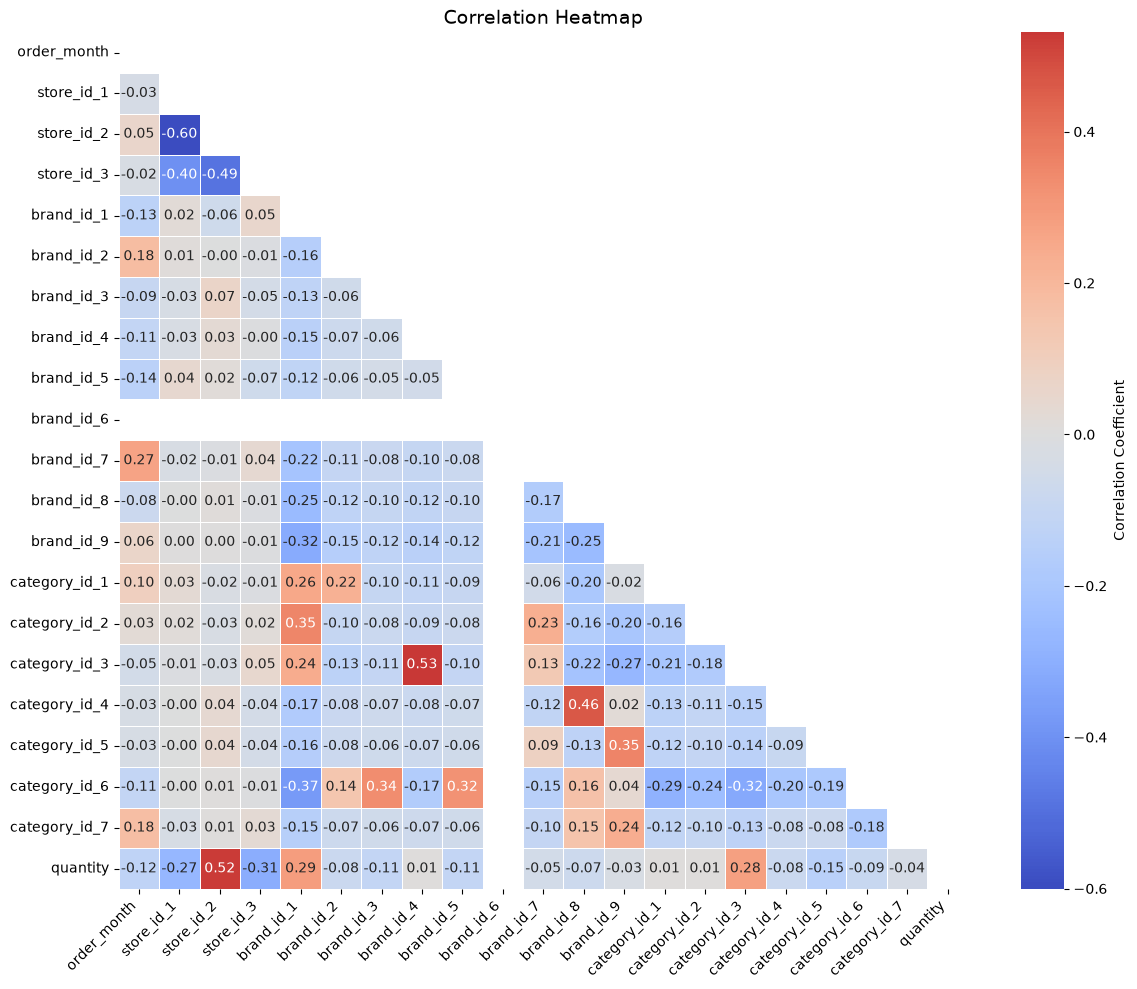

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_full = X_train.copy()
train_full['quantity'] = y_train

corr_matrix = train_full.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask,             
    annot=True,            
    fmt='.2f',             
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5, 
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title('Correlation Heatmap', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
X_test

,order_month,store_id_1,store_id_2,store_id_3,brand_id_1,brand_id_2,brand_id_3,brand_id_4,brand_id_5,brand_id_6,brand_id_7,brand_id_8,brand_id_9,category_id_1,category_id_2,category_id_3,category_id_4,category_id_5,category_id_6,category_id_7
23,25,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
24,26,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
25,27,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
26,28,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
48,25,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
959,28,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
971,25,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
972,26,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
973,27,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [13]:
X_train

,order_month,store_id_1,store_id_2,store_id_3,brand_id_1,brand_id_2,brand_id_3,brand_id_4,brand_id_5,brand_id_6,brand_id_7,brand_id_8,brand_id_9,category_id_1,category_id_2,category_id_3,category_id_4,category_id_5,category_id_6,category_id_7
0,1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
966,20,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
967,21,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
968,22,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
969,23,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [14]:
y_test

23      4
24      3
25      2
26     22
48      2
       ..
959     6
971     4
972     6
973     5
974     9
Name: quantity, Length: 166, dtype: int64

In [15]:
y_train

0      6
1      8
2      2
3      6
4      3
      ..
966    6
967    5
968    1
969    1
970    1
Name: quantity, Length: 809, dtype: int64

XG Boost model

In [16]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

xgb_model = xgb.XGBRegressor(
    n_estimators=100,      
    learning_rate=0.1,     
    max_depth=4,            
    random_state=42,
    n_jobs=-1              
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"MSE (XGBoost): {mse_xgb:.4f}")
print(f"RMSE (XGBoost): {rmse_xgb:.4f}")
print(f"R2 Score (XGBoost): {r2_xgb:.4f}")

MSE (XGBoost): 62.4760
RMSE (XGBoost): 7.9042
R2 Score (XGBoost): 0.3396


Prediction

In [17]:
comb_real = df[['store_id', 'brand_id', 'category_id']].drop_duplicates()

fut_list = []
for mes in range(29, 37):
    temp = comb_real.copy()
    temp['order_month'] = mes
    fut_list.append(temp)

df_future = pd.concat(fut_list, ignore_index=True)

future_encoded = pd.get_dummies(df_future, columns=['store_id', 'brand_id', 'category_id'])

X_future = future_encoded.reindex(columns=X_train.columns, fill_value=0)

df_future['predicted_quantity'] = xgb_model.predict(X_future)

df_future

,store_id,brand_id,category_id,order_month,predicted_quantity
0,1,1,1,29,6.054125
1,1,1,2,29,3.231340
2,1,1,3,29,9.272002
3,1,1,5,29,5.093354
4,1,2,1,29,2.462992
...,...,...,...,...,...
539,3,9,1,36,1.222652
540,3,9,4,36,1.590439
541,3,9,5,36,0.734892
542,3,9,6,36,2.902932


In [18]:
month_sum = df_future.groupby('order_month')['predicted_quantity'].sum()

print(month_sum)

order_month
29    299.146637
30    299.146637
31    299.146637
32    299.146637
33    299.146637
34    299.146637
35    299.146637
36    299.146637
Name: predicted_quantity, dtype: float32


In [19]:
importances = pd.DataFrame({'Feature': X_train.columns, 'Importance': xgb_model.feature_importances_}).sort_values(by='Importance', ascending=False)

print(importances)

          Feature  Importance
4      brand_id_1    0.215733
2      store_id_2    0.135167
15  category_id_3    0.133703
7      brand_id_4    0.078128
14  category_id_2    0.066788
17  category_id_5    0.056799
6      brand_id_3    0.051513
12     brand_id_9    0.048345
16  category_id_4    0.038674
19  category_id_7    0.036171
8      brand_id_5    0.031449
18  category_id_6    0.022971
13  category_id_1    0.017669
0     order_month    0.014917
1      store_id_1    0.013158
11     brand_id_8    0.012956
3      store_id_3    0.012054
10     brand_id_7    0.011650
5      brand_id_2    0.002155
9      brand_id_6    0.000000


In [20]:
df_future = df_future.drop_duplicates(subset=['store_id', 'brand_id', 'category_id', 'predicted_quantity'],keep='first')
df_future

,store_id,brand_id,category_id,order_month,predicted_quantity
0,1,1,1,29,6.054125
1,1,1,2,29,3.231340
2,1,1,3,29,9.272002
3,1,1,5,29,5.093354
4,1,2,1,29,2.462992
...,...,...,...,...,...
63,3,9,1,29,1.222652
64,3,9,4,29,1.590439
65,3,9,5,29,0.734892
66,3,9,6,29,2.902932


In [21]:
df_future['predicted_quantity'] = df_future['predicted_quantity'].round().astype(int)
df_future

,store_id,brand_id,category_id,order_month,predicted_quantity
0,1,1,1,29,6
1,1,1,2,29,3
2,1,1,3,29,9
3,1,1,5,29,5
4,1,2,1,29,2
...,...,...,...,...,...
63,3,9,1,29,1
64,3,9,4,29,2
65,3,9,5,29,1
66,3,9,6,29,3


In [22]:
df_future['predicted_quantity'].sum()

np.int64(297)

In [23]:
df_future = df_future.drop(columns=['order_month'])
df_future

,store_id,brand_id,category_id,predicted_quantity
0,1,1,1,6
1,1,1,2,3
2,1,1,3,9
3,1,1,5,5
4,1,2,1,2
...,...,...,...,...
63,3,9,1,1
64,3,9,4,2
65,3,9,5,1
66,3,9,6,3


In [24]:
df_future

,store_id,brand_id,category_id,predicted_quantity
0,1,1,1,6
1,1,1,2,3
2,1,1,3,9
3,1,1,5,5
4,1,2,1,2
...,...,...,...,...
63,3,9,1,1
64,3,9,4,2
65,3,9,5,1
66,3,9,6,3


# Merging Demand vs Stock

In [25]:
import pandas as pd

df_stock = pd.read_csv('stock.csv')

df_stock

,store_id,store_name,product_id,product_name,category_id,category_name,brand_id,brand_name,model_year,stock_quantity
0,1,Santa Cruz Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,27
1,2,Baldwin Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,14
2,3,Rowlett Bikes,1,Trek 820 - 2016,6,Mountain Bikes,9,Trek,2016,14
3,1,Santa Cruz Bikes,2,Ritchey Timberwolf Frameset - 2016,6,Mountain Bikes,5,Ritchey,2016,5
4,2,Baldwin Bikes,2,Ritchey Timberwolf Frameset - 2016,6,Mountain Bikes,5,Ritchey,2016,16
...,...,...,...,...,...,...,...,...,...,...
934,2,Baldwin Bikes,312,Electra Townie Commute 8D Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,2
935,3,Rowlett Bikes,312,Electra Townie Commute 8D Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,18
936,1,Santa Cruz Bikes,313,Electra Townie Original 1 Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,14
937,2,Baldwin Bikes,313,Electra Townie Original 1 Ladies' - 2018,2,Comfort Bicycles,1,Electra,2018,24


In [26]:
df_stock = df_stock[['store_id', 'category_id', 'brand_id', 'stock_quantity']]
df_stock

,store_id,category_id,brand_id,stock_quantity
0,1,6,9,27
1,2,6,9,14
2,3,6,9,14
3,1,6,5,5
4,2,6,5,16
...,...,...,...,...
934,2,2,1,2
935,3,2,1,18
936,1,2,1,14
937,2,2,1,24


In [27]:
df_stock = df_stock.groupby(['store_id', 'category_id', 'brand_id'], as_index=False)['stock_quantity'].sum()
df_stock

,store_id,category_id,brand_id,stock_quantity
0,1,1,1,479
1,1,1,2,51
2,1,1,6,65
3,1,1,7,11
4,1,1,9,346
...,...,...,...,...
64,3,6,7,3
65,3,6,8,195
66,3,6,9,542
67,3,7,8,85


In [28]:
keys = ['store_id', 'category_id', 'brand_id']

df_merged = pd.merge(df_stock, df_future, on=keys, how='outer')

df_merged = df_merged.fillna(1)
df_merged.loc[df_merged['predicted_quantity'] <= 0, 'predicted_quantity'] = 1
df_merged['predicted_quantity'] = df_merged['predicted_quantity'].round().astype(int)

df_merged

,store_id,category_id,brand_id,stock_quantity,predicted_quantity
0,1,1,1,479,6
1,1,1,2,51,2
2,1,1,6,65,3
3,1,1,7,11,2
4,1,1,9,346,3
...,...,...,...,...,...
64,3,6,7,3,1
65,3,6,8,195,3
66,3,6,9,542,3
67,3,7,8,85,1


In [29]:
df_merged = df_merged.rename(columns={'predicted_quantity': 'pred_month_demand'})

In [30]:
df_filter = df.drop(columns=['order_year', 'order_month'])

df_grouped = df_filter.groupby(
    ['store_id', 'brand_id', 'category_id'], 
    as_index=False
)['quantity'].mean()

df_grouped['quantity'] = df_grouped['quantity'].round().astype(int)

df_grouped

,store_id,brand_id,category_id,quantity
0,1,1,1,6
1,1,1,2,4
2,1,1,3,10
3,1,1,5,5
4,1,2,1,2
...,...,...,...,...
63,3,9,1,2
64,3,9,4,2
65,3,9,5,2
66,3,9,6,4


In [31]:
keys = ['store_id', 'brand_id', 'category_id']

df_merged = pd.merge(df_merged, df_grouped, on=keys, how='left')
df_merged = df_merged.rename(columns={'quantity': 'avg_month_demand'})


df_merged

,store_id,category_id,brand_id,stock_quantity,pred_month_demand,avg_month_demand
0,1,1,1,479,6,6.0
1,1,1,2,51,2,2.0
2,1,1,6,65,3,5.0
3,1,1,7,11,2,1.0
4,1,1,9,346,3,4.0
...,...,...,...,...,...,...
64,3,6,7,3,1,2.0
65,3,6,8,195,3,3.0
66,3,6,9,542,3,4.0
67,3,7,8,85,1,1.0


In [32]:
df_merged['max_month_demand'] = df_merged[['pred_month_demand', 'avg_month_demand']].max(axis=1)

df_merged

,store_id,category_id,brand_id,stock_quantity,pred_month_demand,avg_month_demand,max_month_demand
0,1,1,1,479,6,6.0,6.0
1,1,1,2,51,2,2.0,2.0
2,1,1,6,65,3,5.0,5.0
3,1,1,7,11,2,1.0,2.0
4,1,1,9,346,3,4.0,4.0
...,...,...,...,...,...,...,...
64,3,6,7,3,1,2.0,2.0
65,3,6,8,195,3,3.0,3.0
66,3,6,9,542,3,4.0,4.0
67,3,7,8,85,1,1.0,1.0


In [33]:
df_merged.dtypes

store_id               int64
category_id            int64
brand_id               int64
stock_quantity         int64
pred_month_demand      int64
avg_month_demand     float64
max_month_demand     float64
dtype: object

In [34]:
df_merged['avg_month_demand'] = df_merged['avg_month_demand'].fillna(0).astype(int)
df_merged['max_month_demand'] = df_merged['max_month_demand'].fillna(0).astype(int)
df_merged['avg_month_demand'] = df_merged['avg_month_demand'].astype(int)
df_merged['max_month_demand'] = df_merged['max_month_demand'].astype(int)

In [35]:
df_merged['months_of_stock'] = df_merged['stock_quantity'] / df_merged['max_month_demand']

df_merged['months_of_stock'] = df_merged['months_of_stock'].round().astype(int)

df_merged

,store_id,category_id,brand_id,stock_quantity,pred_month_demand,avg_month_demand,max_month_demand,months_of_stock
0,1,1,1,479,6,6,6,80
1,1,1,2,51,2,2,2,26
2,1,1,6,65,3,5,5,13
3,1,1,7,11,2,1,2,6
4,1,1,9,346,3,4,4,86
...,...,...,...,...,...,...,...,...
64,3,6,7,3,1,2,2,2
65,3,6,8,195,3,3,3,65
66,3,6,9,542,3,4,4,136
67,3,7,8,85,1,1,1,85


In [36]:
df_merged['safety_stock'] = (df_merged['max_month_demand'] + 8) * 12
df_merged

,store_id,category_id,brand_id,stock_quantity,pred_month_demand,avg_month_demand,max_month_demand,months_of_stock,safety_stock
0,1,1,1,479,6,6,6,80,168
1,1,1,2,51,2,2,2,26,120
2,1,1,6,65,3,5,5,13,156
3,1,1,7,11,2,1,2,6,120
4,1,1,9,346,3,4,4,86,144
...,...,...,...,...,...,...,...,...,...
64,3,6,7,3,1,2,2,2,120
65,3,6,8,195,3,3,3,65,132
66,3,6,9,542,3,4,4,136,144
67,3,7,8,85,1,1,1,85,108


In [37]:
totals = {
    'stock_quantity': df_merged['stock_quantity'].sum(),
    'pred_month_demand': df_merged['pred_month_demand'].sum(),
    'avg_month_demand': df_merged['avg_month_demand'].sum(),
    'max_month_demand': df_merged['max_month_demand'].sum(),
    '1 year stock': df_merged['safety_stock'].sum()}
df_totals = pd.DataFrame([totals])
display(df_totals)

,stock_quantity,pred_month_demand,avg_month_demand,max_month_demand,1 year stock
0,13511,299,365,391,11316


In [38]:
df_merged.dtypes

store_id             int64
category_id          int64
brand_id             int64
stock_quantity       int64
pred_month_demand    int64
avg_month_demand     int64
max_month_demand     int64
months_of_stock      int64
safety_stock         int64
dtype: object

In [39]:
df_merged.to_csv('df_merged.csv', index=False)